In [1]:
import pandas as pd
import scipy as sc
import numpy as np
import h5py
import matplotlib.pylab as plt

In [2]:
data_train= "cat_not_cat/train_catvnoncat.h5"
train_dataset = h5py.File(data_train, "r")

data_test= "cat_not_cat/test_catvnoncat.h5"
test_dataset = h5py.File(data_test, "r")

In [3]:
train_dataset.keys()

<KeysViewHDF5 ['list_classes', 'train_set_x', 'train_set_y']>

In [4]:
## extraer daatos
xtrain_classes, xtrain, train_label = \
train_dataset["list_classes"],train_dataset["train_set_x"],train_dataset["train_set_y"]

test_classes, xtest, test_label = \
test_dataset["list_classes"],test_dataset["test_set_x"],test_dataset["test_set_y"]

In [5]:
np.shape(xtrain)


(209, 64, 64, 3)

In [6]:
xtrain = np.array(xtrain)
xtrain_plane = xtrain.reshape(xtrain.shape[0],-1)/255

In [40]:
xtest = np.array(xtest)
xtest_plane = xtest.reshape(xtest.shape[0],-1)/255

In [7]:
xtrain_plane


array([[0.06666667, 0.12156863, 0.21960784, ..., 0.        , 0.        ,
        0.        ],
       [0.76862745, 0.75294118, 0.74509804, ..., 0.32156863, 0.31372549,
        0.31764706],
       [0.32156863, 0.27843137, 0.26666667, ..., 0.54117647, 0.55294118,
        0.55686275],
       ...,
       [0.56078431, 0.60784314, 0.64705882, ..., 0.33333333, 0.41960784,
        0.58431373],
       [0.08627451, 0.09411765, 0.09019608, ..., 0.01568627, 0.01960784,
        0.        ],
       [0.03137255, 0.10980392, 0.20784314, ..., 0.        , 0.        ,
        0.        ]])

In [8]:
np.shape(xtrain_plane)

(209, 12288)

In [9]:
train_label = np.array(train_label)
train_label

array([0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [10]:
len(train_label)

209

In [22]:
64*64*3

12288

In [24]:
N = 64*64*3

In [5]:
train_label[169]

np.int64(1)

In [6]:
np.shape(xtrain)

(209, 64, 64, 3)

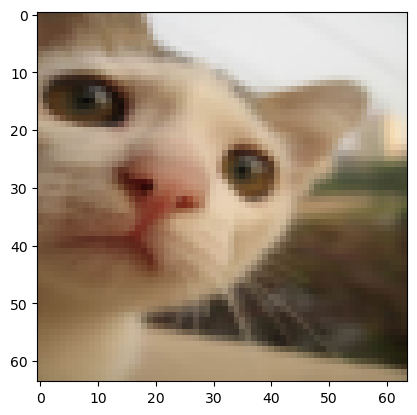

In [7]:
plt.imshow(xtrain[169])

In [8]:
np.shape(xtrain[0]) # ver dimension del array de la imagen

(64, 64, 3)

In [9]:
np.reshape(xtrain[0], 64*64*3)/255  # convertir a array columna de dimension 64*64*3 y normalizar

array([0.06666667, 0.12156863, 0.21960784, ..., 0.        , 0.        ,
       0.        ])

In [11]:
def act_function(name, x):
    if name == 'sigmoid':
        # definir el sigmoide
        f = lambda x: 1 / (1 + np.exp(-x))
        # derivada del sigmoide
        fp = f(x) * (1 - f(x))
        return np.array([f(x), fp])

    if name == 'relu':
        # Función ReLU (Para el forward propagation)
        f = lambda x: np.maximum(0,x)
        fp = (x > 0).astype(float)
        return np.array([f(x), fp])

    else:
        raise ValueError("Funcion de activacion no definida")


class layer():
    """
    Esta clase representa una capa de una red neuronal.
    Contiene los pesos y el sesgo de la capa, así como
    un método para calcular la salida de la capa como un
    conjunto de entradas
    nL es el bumero de neuronas y nL el numero de inputs
    """
    def __init__(self, nlayer, neus, nparams, name):
        # Inicializa los parametros theta y B de la capa con valores aleatorios
        self.theta = 0.001*(2 * np.random.random((neus, nparams)) - 1)  # cada fila representa una neuronas distinta, y cada columna un parametro
        self.B = 0.001*(2 * np.random.random((neus, 1)) - 1)
        self.num_serie = nlayer
        # Almacena el nombre de la funcion de activacion
        self.name = name

    def output(self, X):
        """
        Calcula la salida de la capa dado un conjunto de entradas A.
        La salida se calcula como Z = theta * A + B y luego se aplica la
        funcion de activacion
        """
        # Calcula la salida de la capa
        self.Z = self.theta @ X + self.B
        # Aplica la funcion de activacion a la salida
        F = act_function(self.name, self.Z)
        # Almacena la salida de la capa y su derivada
        self.A = np.array(F[0])
        self.Ap = np.array(F[1])

    def back_propagation(self, red, y, alpha, X):
        L = len(red)  # Para saber cuál es la última capa

        # 1. Calcular la transferencia de esta capa
        if self.num_serie == L:
            # Última capa: error directo simplificado
            self.transferencia = self.A - y
        else:
            # Capa oculta: usa la transferencia de la capa siguiente
            # y su theta ANTES de ser actualizado (theta_old)
            capa_siguiente = red[self.num_serie]
            self.transferencia = (capa_siguiente.theta_old.T @ capa_siguiente.transferencia) * self.Ap

        # 2. Identificar qué A_prev se va a multiplicar
        if self.num_serie == 1:
            entrada_anterior = X
        else:
            entrada_anterior = red[self.num_serie - 2].A

        # 3. Calcular las derivadas, promediando sobre los m ejemplos
        m = X.shape[1]
        derivada = (self.transferencia @ entrada_anterior.T) / m
        derivada_b = np.sum(self.transferencia, axis=1, keepdims=True) / m

        # 4. Guardar el theta viejo (lo necesita la capa anterior) y actualizar
        self.theta_old = self.theta.copy()
        self.theta = self.theta - alpha * derivada
        self.B = self.B - alpha * derivada_b

    def num_neurons(self):
        """
        Dvuelve el número de neuronas de la capa
        """
        return self.theta.shape[0]

In [25]:
N = 64*64*3
Topology = [N,128,32,8,1]
acts = ['relu', 'relu', 'relu', 'sigmoid']
red = []

# Crear layers
for i in range (len(Topology) - 1):
    nn = layer(i+1,Topology[i+1],Topology[i],acts[i])   ## numero de neuronas; numero de entradas. El numero de neuronas de la l ésima capa es el número de salidas de la anterior capa
    red.append(nn)

# Calcular funcion de activacion y su derivada
red[0].output(xtrain_plane[5:6].T)
for i in range (1, len(Topology) - 1):
    red[i].output(red[i-1].A)


# Propagar hacia atras
L = len(red) -  1
for i in range(L, -1, -1):
    #red[i].back_propagation(red, train_label[5], 0.2, red[i-1])
    red[i].back_propagation(red, train_label[5], 0.2, xtrain_plane[5:6].T)



print("La predicción es ", red[-1].A)


La predicción es  [[0.50017293]]


In [26]:
# 1. Preparar las matrices para las 209 imágenes juntas
# xtrain_plane es (209, 12288) -> X_todo será (12288, 209)
X_todo = xtrain_plane.T 

# Asegurar que las etiquetas sean una fila (1, 209)
Y_todo = train_label.reshape(1, -1) 

# 2. Configurar el entrenamiento
epocas = 100  # Cantidad de veces que la red verá el dataset completo
alpha = 0.05  # Tasa de aprendizaje

# 3. Bucle principal de entrenamiento
for epoca in range(epocas):
    
    # --- FORWARD PROPAGATION ---
    red[0].output(X_todo)
    for i in range(1, len(Topology) - 1):
        red[i].output(red[i-1].A)
        
    # --- BACK PROPAGATION ---
    L = len(red) - 1
    for i in range(L, -1, -1):
        red[i].back_propagation(red, Y_todo, alpha, X_todo)
        
    # --- MONITOREO ---
    # Imprimir el costo cada 10 épocas para ver si de verdad está aprendiendo
    if epoca % 10 == 0:
        # A_final tiene las 209 predicciones: forma (1, 209)
        A_final = red[-1].A 
        
        # Fórmula de Entropía Cruzada Binaria (Costo)
        # Se suma un número minúsculo (1e-15) para evitar el log(0) que da error
        costo = -np.mean(Y_todo * np.log(A_final + 1e-15) + (1 - Y_todo) * np.log(1 - A_final + 1e-15))
        
        print(f"Época {epoca} | Costo: {costo:.4f}")

Época 0 | Costo: 0.6789
Época 10 | Costo: 0.6713
Época 20 | Costo: 0.6654
Época 30 | Costo: 0.6608
Época 40 | Costo: 0.6572
Época 50 | Costo: 0.6544
Época 60 | Costo: 0.6522
Época 70 | Costo: 0.6504
Época 80 | Costo: 0.6491
Época 90 | Costo: 0.6480


In [41]:
# 1. Preparar las matrices para las 209 imágenes juntas
# xtrain_plane es (209, 12288) -> X_todo será (12288, 209)
X_test = xtest_plane 

# Asegurar que las etiquetas sean una fila (1, 209)
test_label = np.array(test_label)
Y_test = test_label.reshape(1, -1) 



# Forward sobre todo el conjunto de test
A = X_test.T                      # shape (N, m_test)
for capa in red:
    capa.output(A)
    A = capa.A

probs = red[-1].A                 # shape (1, m_test)
preds = (probs >= 0.5).astype(int).flatten()
y_real = np.array(Y_test).flatten()

aciertos = np.sum(preds == y_real)
total = len(y_real)

print(f"Acertó {aciertos} de {total} ({100 * aciertos / total:.2f}%)")

Acertó 17 de 50 (34.00%)


In [42]:
tp = np.sum((preds == 1) & (y_real == 1))   # gatos bien detectados
tn = np.sum((preds == 0) & (y_real == 0))   # no-gatos bien detectados
fp = np.sum((preds == 1) & (y_real == 0))   # dijo gato y no lo era
fn = np.sum((preds == 0) & (y_real == 1))   # dijo no-gato y sí lo era

print(f"Gatos bien detectados:     {tp}")
print(f"No-gatos bien detectados:  {tn}")
print(f"Falsos positivos:          {fp}")
print(f"Falsos negativos:          {fn}")

Gatos bien detectados:     0
No-gatos bien detectados:  17
Falsos positivos:          0
Falsos negativos:          33


In [36]:
np.shape(Y_test)

(1, 50)